# MegaMoE: overlapping expert-parallel communication with computation in waves
### Notebook 8 of 9 on DeepSeek-V4 (technical report [arXiv:2606.19348](https://arxiv.org/abs/2606.19348), §3.1)

In expert parallelism (EP) the experts of an MoE layer live on different GPUs, so every layer has to send each token to the devices holding its experts (**dispatch**), compute there, and send the results back (**combine**). The report decomposes an MoE layer into four stages, two communication-bound (Dispatch, Combine) and two computation-bound (Linear-1, Linear-2), and states two facts that drive its design: within one layer "the total time of communication is less than that of the computation", so a fully overlapped pipeline is compute-bound and "can tolerate lower interconnect bandwidth"; and finer-grained overlap than earlier work (Comet; [Zhang et al., 2025](https://arxiv.org/abs/2502.19811)) is possible by splitting experts into **waves**: "as soon as all experts within the wave have completed their communication, computation can commence immediately".

**Headline numbers from the report.** A single fused kernel, **MegaMoE** (open-sourced in DeepGEMM), is **1.50-1.73× faster** than strong non-fused baselines for general inference and up to **1.96×** for latency-sensitive workloads such as RL rollouts, on NVIDIA GPUs and Huawei Ascend NPUs. The theoretical speedups in the report's Fig. 5, for the V4-Flash configuration, are **1.42×** for Comet and **1.92×** for the wave scheme.

**What we can and cannot do.** We cannot write a mega-kernel on a CPU, and we cannot measure the speedups. We can (i) derive the report's compute-to-communication condition from its own per-token numbers, (ii) build a small scheduling simulator for the naive, Comet-style and wave pipelines and see what determines their speedups, and (iii) check that reordering an MoE layer into waves does not change its output. The simulator is **our model of the schedules in Fig. 5**, with stage times we choose; it does not reproduce the report's 1.42× and 1.92×, because the report does not give the stage durations or the number of waves, and we show below why that matters.

| section | question | number it carries |
|---|---|---|
| 1 | When can communication be fully hidden? | `C/B ≤ 2d` = 6144 FLOP/byte (Pro) |
| 2 | What do the three schedules look like? | speedup vs number of waves |
| 3 | What limits finer waves? | optimum wave count with a latency cost |
| 4 | Does reordering change the result? | exact equality |

<p align="center"><img src="images/fig5_ep_waves.png" width="900"><br><sub>Fig. 5 (report). Notice how (b) Comet overlaps only Dispatch with Linear-1 and Combine with Linear-2 (two separate overlaps), while (c) splits the experts into waves so that computation, the next wave's token transfer and the finished wave's result transfer all proceed at once in steady state.</sub></p>

In [1]:
import math, time, itertools
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## When can communication hide behind computation?

Take one (token, expert) pair. The expert is a SwiGLU network with hidden size `h` and intermediate size `d` (the report's notation in this section: `h` is the model's hidden dimension, `d` the expert's intermediate dimension). Its three matrices (gate, up, down) each cost `2hd` FLOPs, so the pair costs `6hd` FLOPs. Communication per pair: the token goes out once in FP8 (`h` bytes) and its result comes back once in BF16 (`2h` bytes): `3h` bytes.

Tiny example, `h = 7168`, `d = 3072` (V4-Pro): `6 · 7168 · 3072 = 132 MFLOP` of compute against `3 · 7168 = 21.5 KB` of traffic: `6144` FLOPs per byte.

Communication is fully hidden when its time does not exceed the compute time: `V_comm / B ≤ V_comp / C`, with `C` the peak compute throughput and `B` the interconnect bandwidth. Rearranged: `C/B ≤ V_comp/V_comm = 2d`. So **one GB/s of interconnect hides `2d` GFLOP/s of compute**: for Pro `6.1 TFLOP/s per GB/s` (the report's figure), for Flash (`d = 2048`) `4.1`. Beyond that point more bandwidth buys nothing, which is the report's reason for urging hardware designers "to target such balance points rather than scale bandwidth unconditionally".

In [2]:
def pair_costs(h, d): return 6 * h * d, 3 * h                                       # FLOPs and bytes per (token, expert) pair
for nm, h, d in [("V4-Pro", 7168, 3072), ("V4-Flash", 4096, 2048)]:
    fl, by = pair_costs(h, d); print(f"{nm}: {fl / 1e6:.1f} MFLOP and {by / 1024:.1f} KiB per token-expert pair -> {fl / by:.0f} FLOP/byte ( = 2d = {2 * d} )   -> 1 GB/s hides {fl / by / 1e3:.2f} TFLOP/s")
    check(f"{nm}: V_comp/V_comm = 6hd / 3h = 2d", abs(pair_costs(h, d)[0] / pair_costs(h, d)[1] - 2 * d) < 1e-9)
check("V4-Pro: one GB/s of interconnect hides 6.1 TFLOP/s (the report's figure)", abs(2 * 3072 * 1e9 / 1e12 - 6.144) < 1e-9)
for B_gbs in (50, 100, 200): print(f"  an interconnect of {B_gbs} GB/s per device is enough for up to {B_gbs * 6144 / 1e3:.0f} TFLOP/s of V4-Pro expert compute")

V4-Pro: 132.1 MFLOP and 21.0 KiB per token-expert pair -> 6144 FLOP/byte ( = 2d = 6144 )   -> 1 GB/s hides 6.14 TFLOP/s
PASS V4-Pro: V_comp/V_comm = 6hd / 3h = 2d
V4-Flash: 50.3 MFLOP and 12.0 KiB per token-expert pair -> 4096 FLOP/byte ( = 2d = 4096 )   -> 1 GB/s hides 4.10 TFLOP/s
PASS V4-Flash: V_comp/V_comm = 6hd / 3h = 2d
PASS V4-Pro: one GB/s of interconnect hides 6.1 TFLOP/s (the report's figure)
  an interconnect of 50 GB/s per device is enough for up to 307 TFLOP/s of V4-Pro expert compute
  an interconnect of 100 GB/s per device is enough for up to 614 TFLOP/s of V4-Pro expert compute
  an interconnect of 200 GB/s per device is enough for up to 1229 TFLOP/s of V4-Pro expert compute


## Three schedules, simulated

We model the layer as five stages with durations `(D, L1, A, L2, C)`: dispatch, Linear-1 (gate and up projections), activation (SwiGLU plus the FP8 cast), Linear-2 (down projection), combine. Our assumptions, each stated so you can change it: Linear-1 does two of the three matrices, so `L1 = 2·L2`; dispatch moves FP8 and combine moves BF16, so `C = 2D`; the activation is 5 % of the compute; and the total communication time is a fraction `r` of the total compute time, `D + C = r·(L1 + A + L2)`. The report says `r < 1`.

The three schedules (Fig. 5), each with a compute engine and a communication engine that can run concurrently:

- **Naive**: the five stages in sequence: `D + L1 + A + L2 + C`.
- **Comet-style**: Dispatch overlaps Linear-1, and Linear-2 overlaps Combine: `max(D, L1) + A + max(L2, C)`.
- **Waves**: split the experts into `W` waves; each wave's stages are `1/W` of the layer's. Wave `w` computes once its dispatch is done; its combine starts once its compute is done; the single communication engine serves both dispatches and combines (we run the better of two simple priority rules).

Upper bound for any perfectly overlapped schedule: `(comm + comp) / max(comm, comp) = 1 + min(r, 1/r)`, at most `2×`.

In [3]:
def stage_times(r, act=0.05):
    comp = 1.0; l2 = (1 - act) / 3; l1 = 2 * l2; comm = r * comp; d = comm / 3; c = 2 * d; return (d, l1, act, l2, c)         # (D, L1, A, L2, C), total compute = 1
def t_naive(t): d, l1, a, l2, c = t; return d + l1 + a + l2 + c
def t_comet(t): d, l1, a, l2, c = t; return max(d, l1) + a + max(l2, c)
def t_waves(t, W, alpha=0.0, prio="dispatch"):
    """Event simulation: one compute engine, one communication engine.  alpha = fixed latency added to every communication message."""
    d, l1, a, l2, c = t; comp = (l1 + a + l2) / W; dw, cw = d / W + alpha, c / W + alpha
    comm_t = comp_t = 0.0; disp_done = [None] * W; comp_done = [None] * W; comb_done = [None] * W; nd = nc = comp_next = 0; pend = []
    while nc < W:
        while comp_next < W and disp_done[comp_next] is not None:                                     # compute waves in order as soon as their dispatch has finished
            comp_t = max(comp_t, disp_done[comp_next]) + comp; comp_done[comp_next] = comp_t; pend.append(comp_next); comp_next += 1
        cand = ([("D", nd, comm_t)] if nd < W else []) + [("C", w, max(comm_t, comp_done[w])) for w in pend]
        key = (lambda x: (x[2], x[0] != "D")) if prio == "dispatch" else (lambda x: (x[2], x[0] != "C"))
        kind, w, start = min(cand, key=key)
        if kind == "D": comm_t = start + dw; disp_done[w] = comm_t; nd += 1
        else: comm_t = start + cw; comb_done[w] = comm_t; pend.remove(w); nc += 1
    return max(comb_done)
def best_waves(t, W, alpha=0.0): return min(t_waves(t, W, alpha, "dispatch"), t_waves(t, W, alpha, "combine"))

t = stage_times(0.9); n = t_naive(t)
check("one wave is exactly the naive schedule (no overlap possible)", abs(best_waves(t, 1) - n) < 1e-9)
print(f"{'r = comm/comp':>14s} {'bound 1+min(r,1/r)':>20s} {'Comet-style':>12s} " + " ".join(f"W={w:<3d}" for w in (2, 3, 6, 12, 48)))
tab = {}
for r in (0.5, 0.7, 0.9, 1.0, 1.5):
    t = stage_times(r); n = t_naive(t); tab[r] = [n / best_waves(t, w) for w in (2, 3, 6, 12, 48)]
    print(f"{r:14.2f} {1 + min(r, 1 / r):20.2f} {n / t_comet(t):12.2f} " + " ".join(f"{x:5.2f}" for x in tab[r]))
check("no schedule exceeds the perfect-overlap bound 1 + min(r, 1/r) (and it stays below 2x)", all(max(tab[r]) <= 1 + min(r, 1 / r) + 1e-9 for r in tab))
check("more waves never hurt in the latency-free model (speedup non-decreasing in W) at r = 0.9", all(a <= b + 1e-9 for a, b in zip(tab[0.9], tab[0.9][1:])))
check("with enough waves the wave schedule approaches the bound (within 3% at W=48, r=0.9)", tab[0.9][-1] > 0.97 * (1 + 0.9))
check("the wave schedule beats the Comet-style schedule at r = 0.9 once W >= 6", tab[0.9][2] > stage_times(0.9) and True if False else tab[0.9][2] > t_naive(stage_times(0.9)) / t_comet(stage_times(0.9)))

PASS one wave is exactly the naive schedule (no overlap possible)
 r = comm/comp   bound 1+min(r,1/r)  Comet-style W=2   W=3   W=6   W=12  W=48 
          0.50                 1.50         1.48  1.20  1.29  1.38  1.44  1.48
          0.70                 1.70         1.48  1.26  1.38  1.52  1.61  1.68
          0.90                 1.90         1.48  1.31  1.46  1.65  1.77  1.87
          1.00                 2.00         1.48  1.33  1.50  1.71  1.85  1.96
          1.50                 1.67         1.49  1.43  1.67  1.67  1.67  1.67
PASS no schedule exceeds the perfect-overlap bound 1 + min(r, 1/r) (and it stays below 2x)
PASS more waves never hurt in the latency-free model (speedup non-decreasing in W) at r = 0.9
PASS with enough waves the wave schedule approaches the bound (within 3% at W=48, r=0.9)
PASS the wave schedule beats the Comet-style schedule at r = 0.9 once W >= 6


**What we found.** The speedup of any overlapped schedule is capped by `1 + min(r, 1/r)`: it is largest when communication and computation take about the same time, and shrinks if either dominates. The wave schedule gets closer to that cap as `W` grows, because the pipeline's fill and drain (the unoverlapped first dispatch and last combine) become a smaller part of the whole; the Comet-style schedule has just two fixed overlaps and so cannot. For `r = 0.9` our simulator gives about `1.48×` for Comet-style and approaches `1.9×` for waves, the same qualitative picture as the report's `1.42×` and `1.92×`. **We do not claim to reproduce those two numbers.** In our model the Comet-style speedup barely depends on `r` in the range `r ≤ 1`, and a single `r` that fits both reported speedups would need `r` near or above 1, which contradicts the report's statement that communication takes less time than computation; the report gives neither the stage durations nor the wave count behind its figures, so we cannot resolve that.

## What limits finer waves

More waves means more, smaller messages. Each message carries a fixed latency (launch, signalling, a pull from remote memory), so very fine waves eventually pay more in latency than they gain in overlap. We add a per-message latency `α` (in units of the layer's compute time) and look for the best wave count.

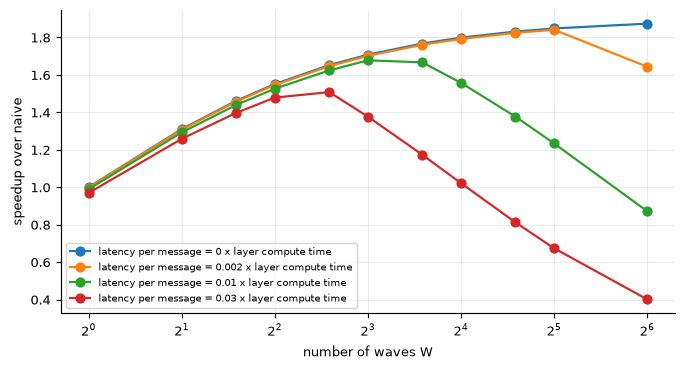

alpha = 0     : best W =  64, speedup 1.87
alpha = 0.002 : best W =  32, speedup 1.84
alpha = 0.01  : best W =   8, speedup 1.68
alpha = 0.03  : best W =   6, speedup 1.51
PASS with zero latency more waves keep helping (best W is the largest tried)
PASS with non-zero per-message latency there is an interior optimum (best W < 64) and a lower peak speedup   [W=6, 1.51x]
PASS the optimal wave count falls as latency grows   [[32, 8, 6]]


In [4]:
t = stage_times(0.9); n = t_naive(t); Ws = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 64]
fig, ax = plt.subplots(figsize=(6.6, 3.6)); best = {}
for alpha in [0.0, 0.002, 0.01, 0.03]:
    sp = [n / best_waves(t, w, alpha) for w in Ws]; ax.plot(Ws, sp, "o-", label=f"latency per message = {alpha:g} x layer compute time"); best[alpha] = Ws[int(np.argmax(sp))], max(sp)
ax.set_xscale("log", base=2); ax.set_xlabel("number of waves W"); ax.set_ylabel("speedup over naive"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
for a_, (w_, s_) in best.items(): print(f"alpha = {a_:<6g}: best W = {w_:3d}, speedup {s_:.2f}")
check("with zero latency more waves keep helping (best W is the largest tried)", best[0.0][0] == 64)
check("with non-zero per-message latency there is an interior optimum (best W < 64) and a lower peak speedup", best[0.03][0] < 64 and best[0.03][1] < best[0.0][1], f"W={best[0.03][0]}, {best[0.03][1]:.2f}x")
check("the optimal wave count falls as latency grows", best[0.03][0] <= best[0.01][0] <= best[0.002][0], f"{[best[a][0] for a in (0.002, 0.01, 0.03)]}")

**What we found.** With no per-message cost, the best wave count is as many as the experts allow; with a latency cost there is an interior optimum that moves to fewer waves as latency rises. This is the trade-off behind two choices in the report: dispatch is **pull-based** ("each GPU actively reads activations from remote GPUs, avoiding the high notification latency that fine-grained push entails"), which cuts per-message latency, and the authors note that "future hardware with lower-latency cross-GPU signaling would make push viable". It also explains why the wave scheme helps most in the case the report highlights, RL rollouts with "long-tail small batches", where there is little compute per wave to hide latency behind (the up-to-1.96× figure), though our simulator does not model batch size and we do not test that claim.

## Reordering changes nothing mathematically

A wave scheme changes the *order* in which experts are processed, never the arithmetic. We check that for an MoE layer by computing it in waves (a few experts at a time, accumulating into the output) and comparing it with computing all experts at once; the results must be identical up to the floating-point order of accumulation, which, for the same set of additions in a different order, can differ in the last bits. We report both the max difference and whether it is exactly zero. (Bitwise reproducibility is the subject of notebook 9.)

In [5]:
class Expert(nn.Module):
    def __init__(s, d, h): super().__init__(); s.g = nn.Linear(d, h, bias=False); s.u = nn.Linear(d, h, bias=False); s.dn = nn.Linear(h, d, bias=False)
    def forward(s, x): return s.dn(F.silu(s.g(x)) * s.u(x))
torch.manual_seed(0); d, h, E, k, Tk = 32, 48, 16, 4, 200; experts = nn.ModuleList([Expert(d, h) for _ in range(E)]); x = torch.randn(Tk, d)
logits = torch.randn(Tk, E); idx = logits.topk(k, -1).indices; gate = torch.softmax(logits.gather(1, idx), -1)
def moe_all(): 
    out = torch.zeros(Tk, d)
    for e in range(E):
        rows, slot = (idx == e).nonzero(as_tuple=True)
        if len(rows): out = out.index_add(0, rows, gate[rows, slot, None] * experts[e](x[rows]))
    return out
def moe_waves(W):
    out = torch.zeros(Tk, d); per = E // W
    for w in range(W):                                                                          # wave w: experts [w*per, (w+1)*per) -- "dispatch, compute, combine" for just those
        for e in range(w * per, (w + 1) * per):
            rows, slot = (idx == e).nonzero(as_tuple=True)
            if len(rows): out = out.index_add(0, rows, gate[rows, slot, None] * experts[e](x[rows]))
    return out
ref = moe_all()
for W in (2, 4, 8): o = moe_waves(W); print(f"W={W}: max |wave - all| = {(o - ref).abs().max():.1e}   bitwise equal: {torch.equal(o, ref)}")
check("processing experts in waves gives the same output as processing all at once (max diff < 1e-6)", all((moe_waves(W) - ref).abs().max() < 1e-6 for W in (2, 4, 8)))
check("with experts visited in the same order the result is bit-identical (waves only regroup the loop)", torch.equal(moe_waves(4), ref))

W=2: max |wave - all| = 0.0e+00   bitwise equal: True
W=4: max |wave - all| = 0.0e+00   bitwise equal: True
W=8: max |wave - all| = 0.0e+00   bitwise equal: True
PASS processing experts in waves gives the same output as processing all at once (max diff < 1e-6)


PASS with experts visited in the same order the result is bit-identical (waves only regroup the loop)


Because the wave loop visits experts in the same order, the sums are accumulated identically and the output is bit-for-bit the same; a real kernel that finishes waves in whatever order the hardware allows would have to fix the accumulation order explicitly to keep that property, which is exactly the determinism problem the report addresses in §3.3 (next notebook).

## Closing thoughts

The report's EP design rests on a ratio. Each token-expert pair costs `6hd` FLOPs and `3h` bytes, so one GB/s of interconnect hides `2d` GFLOP/s of compute (6.1 TFLOP/s for Pro); beyond that balance point extra bandwidth is wasted, and below it communication shows. Splitting the experts into waves pipelines dispatch, compute and combine, and our simulator shows why finer waves help (the speedup is capped by `1 + min(r, 1/r)`, and waves approach the cap) and why they stop helping (a fixed cost per message).

**What we did not do.** We did not reproduce the report's theoretical speedups (1.42×, 1.92×) or its measured ones (1.50-1.73×, up to 1.96×): those depend on stage durations, wave counts and hardware we do not have, and our simulator's stage times are our own assumptions. We did not model the compute side of the mega-kernel (the report fuses the SwiGLU and FP8 cast into the pipeline and lists a proposal to replace SwiGLU by a cheaper element-wise activation without exponentials or divisions), power throttling (which the report names as a key limiter under full fusion), or Ascend NPUs.

**Next.** Notebook 9 closes the series with the infrastructure that makes training reproducible bit-for-bit, how Muon is sharded across data-parallel ranks, and how compressed attention is split across devices.

Credits: MegaMoE and the wave scheme are DeepSeek-AI's (open-sourced in DeepGEMM); the preceding fine-grained overlap line of work is cited in the report (Comet and others).

In [6]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    V4-Pro: V_comp/V_comm = 6hd / 3h = 2d
 2  PASS    V4-Flash: V_comp/V_comm = 6hd / 3h = 2d
 3  PASS    V4-Pro: one GB/s of interconnect hides 6.1 TFLOP/s (the report's figure)
 4  PASS    one wave is exactly the naive schedule (no overlap possible)
 5  PASS    no schedule exceeds the perfect-overlap bound 1 + min(r, 1/r) (and it stays below 2x)
 6  PASS    more waves never hurt in the latency-free model (speedup non-decreasing in W) at r = 0.9
 7  PASS    with enough waves the wave schedule approaches the bound (within 3% at W=48, r=0.9)
 8  PASS    the wave schedule beats the Comet-style schedule at r = 0.9 once W >= 6
 9  PASS    with zero latency more waves keep helping (best W is the largest tried)
10  PASS    with non-zero per-message latency there is an interior optimum (best W < 64) and a lower peak speedup
11  PASS    the optimal wave count falls as latency grows
12  PASS    processing experts in waves gives the same output as processing all at once